In [29]:
import numpy as np

n_iteracoes = 0
escala = 10
n_x = 19 * escala # 190 pontos em x
n_y = 19 * escala # 190 pontos em y

# Valores iniciais da matriz iguais a zero
V = np.zeros((n_x, n_y))
V

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(190, 190))

In [23]:
eletrodos = [
    (5.2, 5.5, 0.8, 8, 0.0),     # barra da esquerda (0 V)
    (13, 5.5, 0.8, 8, 10.0),    # barra da direita  (10 V)
]

eletrodo  = np.zeros((n_x, n_y), dtype=bool) # True onde há eletrodo

for (x0, y0, larg, alt, tensao) in eletrodos:
    i_ini = int(round(x0 * escala))
    i_fim = int(round((x0 + larg) * escala))
    j_ini = int(round(y0 * escala))
    j_fim = int(round((y0 + alt) * escala))

    V[i_ini:i_fim + 1, j_ini:j_fim + 1] = tensao
    eletrodo[i_ini:i_fim + 1, j_ini:j_fim + 1] = True

print("Pontos de eletrodo:", eletrodo.sum())

Pontos de eletrodo: 1458


In [ ]:
erro = 100
iteracoes = 0
erro_limite = 0.01

V_novo = V.copy()

# while erro > erro_limite:
while erro > erro_limite or iteracoes < 3000:

    soma_dif = 0
    contador = 0

    for i in range(n_x):
        for j in range(n_y):
            if not eletrodo[i][j]:
                soma = 0
                n_vizinhos = 0

                # só soma com os vizinhos internos
                if i > 0:
                    soma += V[i-1][j]
                    n_vizinhos += 1
                if i < n_x -1:
                    soma += V[i+1][j]
                    n_vizinhos += 1
                if j > 0:
                    soma += V[i][j-1]
                    n_vizinhos += 1
                if j < n_y -1:
                    soma += V[i][j+1]
                    n_vizinhos += 1

                V_novo[i][j] = soma/n_vizinhos

                # calcula a diferenca
                soma_dif += abs(V_novo[i][j] - V[i][j])
                contador += 1

    erro = soma_dif/contador
    V = V_novo.copy()
    iteracoes += 1

print(f"Convergiu em {iteracoes} iteracoes. Erro = {erro:.5f} V")

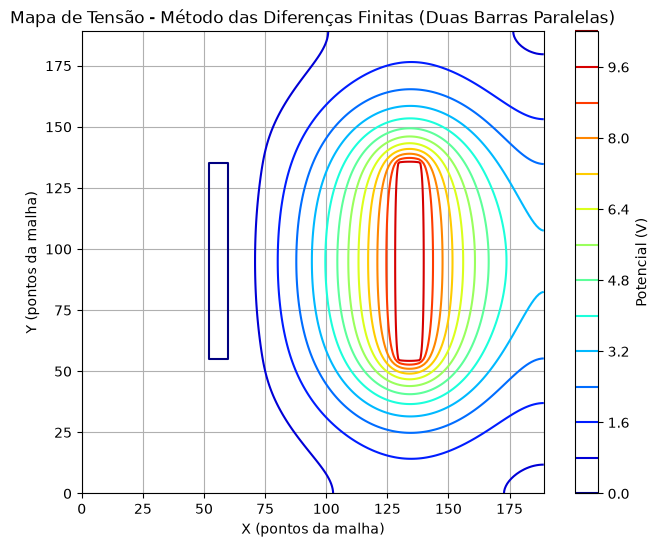

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
cp = plt.contour(V.T, levels=15, cmap="jet")
plt.colorbar(cp, label="Potencial (V)")
plt.title(
    "Mapa de Tensão - Método das Diferenças Finitas (Duas Barras Paralelas)"
)
plt.xlabel("X (pontos da malha)")
plt.ylabel("Y (pontos da malha)")
plt.grid(True)
plt.gca().set_aspect("equal")
plt.show()
